# Kinematical and dynamical electron diffraction

Diffraction patterns of silicon and alpha titanium from quantEM: kinematical patterns with three excitation error models, then Bloch-wave dynamical patterns, thickness and tilt series, CBED, LACBED and Kossel patterns.

Colin Ophus  
Last updated: October 18, 2026

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from ase.build import bulk

from quantem.core.visualization import show_2d
from quantem.diffraction import Crystal, bloch
from quantem.diffraction.crystal import format_direction
from quantem.diffraction.rotations import qmult, quat_from_axis_angle, quat_from_zone_axis

energy_ev = 200e3

In [2]:
def orientation(crystal, uvw, tilt_deg=(0.0, 0.0)):
    """Quaternion that puts a lattice direction (3 or 4 indices) on the beam, then tilts it
    about the lab x and y axes (degrees)."""
    q = quat_from_zone_axis(crystal.direction_vector(uvw)[None])[0]
    for axis, angle in zip(torch.eye(3, dtype=torch.float64)[:2], tilt_deg):
        q = qmult(quat_from_axis_angle(axis, torch.tensor(np.deg2rad(angle))), q)
    return q


def plot_spots(patterns, titles, q_max=1.5, num_labels=8, intensity=None, hexagonal=False, axsize=3.6):
    """Spot patterns in rows: marker area proportional to the square root of the intensity,
    the strongest reflections labeled (hkil for hexagonal crystals)."""
    nr, nc = len(patterns), len(patterns[0])
    fig, axs = plt.subplots(nr, nc, figsize=(axsize * nc, axsize * nr), squeeze=False)
    for r in range(nr):
        for c in range(nc):
            p, ax = patterns[r][c], axs[r, c]
            inten = (p['intensity'] if intensity is None else intensity[r][c]).numpy()
            qx, qy, hkl = p['qx'].numpy(), p['qy'].numpy(), p['hkl'].numpy()
            if hexagonal:
                hkl = np.stack([hkl[:, 0], hkl[:, 1], -hkl[:, 0] - hkl[:, 1], hkl[:, 2]], axis=1)
            keep = np.hypot(qx, qy) < q_max
            size = 300 * np.sqrt(np.clip(inten / inten[keep].max(), 0, None))
            ax.scatter(qy[keep], qx[keep], s=size[keep], c='k', edgecolors='none')
            ax.scatter([0], [0], s=300, facecolors='none', edgecolors='tab:red')
            for k in np.argsort(-inten * keep)[:num_labels]:
                ax.annotate(''.join(str(int(v)) for v in hkl[k]), (qy[k], qx[k]),
                            textcoords='offset points', xytext=(0, 8), ha='center', fontsize=7)
            ax.set_xlim(-q_max, q_max)
            ax.set_ylim(q_max, -q_max)
            ax.set_aspect('equal')
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_title(titles[r][c], fontsize=10)
    fig.tight_layout()
    return fig, axs

# Crystal structures

Silicon (diamond cubic) and alpha titanium (hcp) from ASE. `Crystal` finds the space group and Laue class with spglib, and computes the kinematical structure factors from the Lobato and Van Dyck electron scattering factors.

In [3]:
si = Crystal.from_ase(
    bulk('Si', 'diamond', a=5.431, cubic=True),
    name='Si',
).calculate_structure_factors(k_max=3.0)

ti = Crystal.from_ase(
    bulk('Ti', 'hcp', a=2.9505, c=4.6855),
    name='Ti alpha',
).calculate_structure_factors(k_max=3.0)

Si
  space group      Fd-3m (227)
  point group      m-3m   (Laue class m-3m)
  pseudo-symmetry  none found at tol = 0.01 (0.054 A)
  matching         24 proper rotations, zone axis wedge [001], [011], [111]
Ti alpha
  space group      P6₃/mmc (194)
  point group      6/mmm   (Laue class 6/mmm)
  pseudo-symmetry  none found at tol = 0.01 (0.030 A)
  matching         12 proper rotations, zone axis wedge [0001], [101̅0], [21̅1̅0]


# Kinematical patterns

Low-index zone axes of silicon. The spot intensity is the structure factor squared times a Gaussian envelope in the excitation error, the model used for orientation matching.

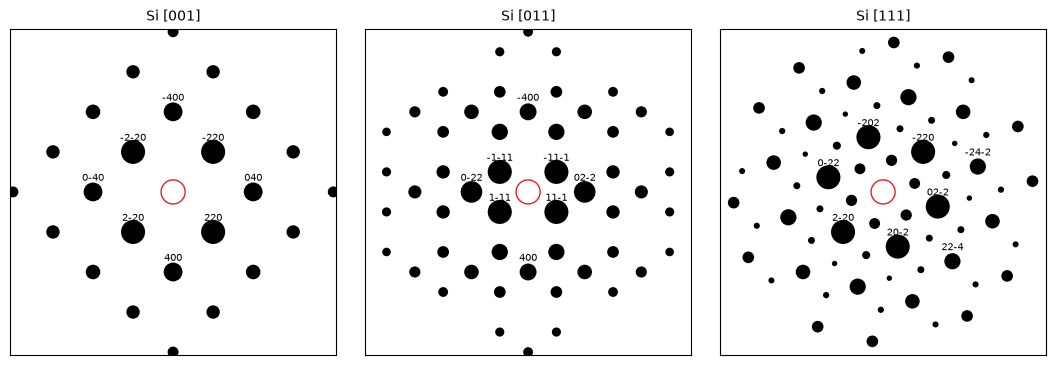

In [4]:
zones_si = [(0, 0, 1), (0, 1, 1), (1, 1, 1)]
patterns = [[
    si.generate_pattern(orientation(si, uvw), energy_ev=energy_ev, k_max=1.5)
    for uvw in zones_si
]]
fig, axs = plot_spots(patterns, [['Si ' + format_direction(z) for z in zones_si]])

Alpha titanium along three zone axes, with four-index Miller-Bravais directions and reflections.

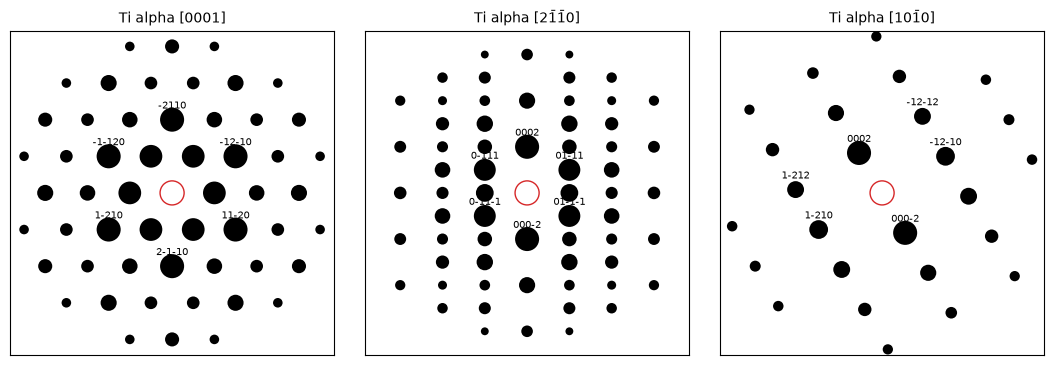

In [5]:
zones_ti = [(0, 0, 0, 1), (2, -1, -1, 0), (1, 0, -1, 0)]
patterns = [[
    ti.generate_pattern(orientation(ti, uvtw), energy_ev=energy_ev, k_max=1.5)
    for uvtw in zones_ti
]]
fig, axs = plot_spots(
    patterns,
    [['Ti alpha ' + format_direction(z) for z in zones_ti]],
    num_labels=6,
    hexagonal=True,
)

# Excitation error models

Silicon [011] tilted 1.5 degrees. The Gaussian envelope has a fixed width `sigma_excitation`, and the slab model uses the rocking curve of a foil of known thickness. Precession averages either envelope over a cone of incident beam directions.

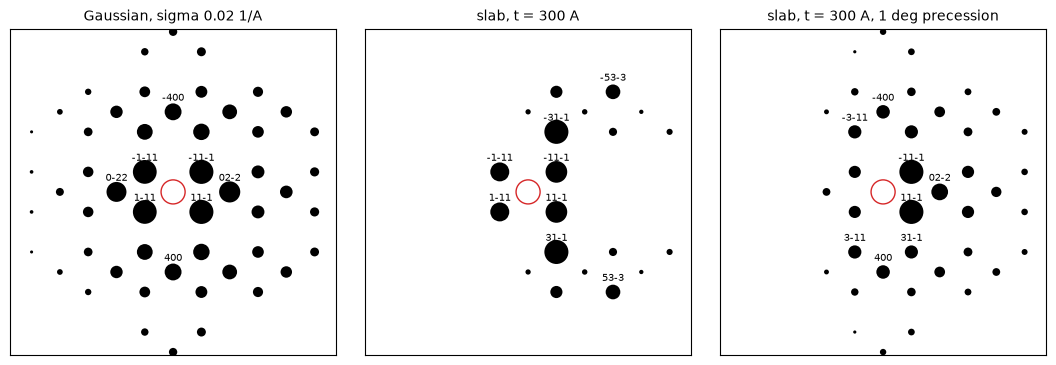

In [6]:
q_tilt = orientation(si, (0, 1, 1), tilt_deg=(1.5, 0.0))
settings = {
    'Gaussian, sigma 0.02 1/A': dict(sigma_excitation=0.02),
    'slab, t = 300 A': dict(excitation_model='slab', thickness_A=300.0),
    'slab, t = 300 A, 1 deg precession': dict(excitation_model='slab', thickness_A=300.0, precession_deg=1.0),
}
patterns = [[
    si.generate_pattern(q_tilt, energy_ev=energy_ev, k_max=1.5, **kwargs)
    for kwargs in settings.values()
]]
fig, axs = plot_spots(patterns, [list(settings)])

# Dynamical diffraction

Bloch-wave calculations need the absorptive Weickenmeier-Kohl structure factors. `dynamical_pattern` diagonalizes the structure matrix once per orientation and returns the exit-surface intensities for every thickness.

In [7]:
si.calculate_dynamical_structure_factors(energy_ev=energy_ev, k_max=3.0)
ti.calculate_dynamical_structure_factors(energy_ev=energy_ev, k_max=3.0)

q_110 = orientation(si, (0, 1, 1))
thicknesses = np.arange(0.0, 2001.0, 10.0)
dyn = bloch.dynamical_pattern(si, q_110, thicknesses, energy_ev=energy_ev, k_max=1.5)
print('%d beams, thicknesses %d to %d A' % (len(dyn['hkl']), thicknesses[0], thicknesses[-1]))

68 beams, thicknesses 0 to 2000 A


Silicon [011] at three thicknesses. The 200 reflections are kinematically forbidden by the diamond glide, but appear in the dynamical patterns by double diffraction (for example 1-11 plus 11-1).

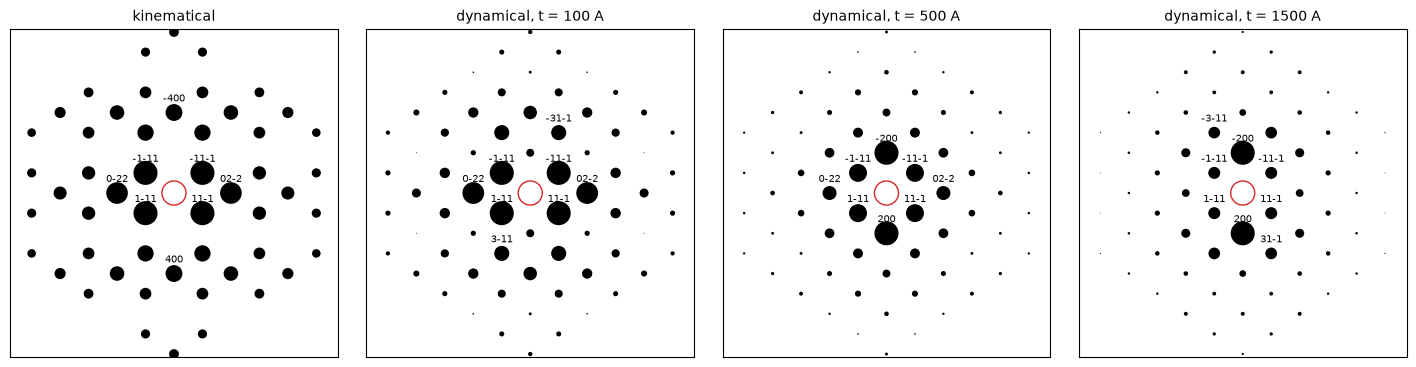

In [8]:
show = [100.0, 500.0, 1500.0]
kin = si.generate_pattern(q_110, energy_ev=energy_ev, k_max=1.5)
patterns = [[kin] + [dyn] * len(show)]
intensity = [[kin['intensity']] + [dyn['intensity'][int(np.argmin(np.abs(thicknesses - t)))] for t in show]]
fig, axs = plot_spots(
    patterns,
    [['kinematical'] + ['dynamical, t = %d A' % t for t in show]],
    intensity=intensity,
)

Pendellösung: the intensity of each beam oscillates with thickness as it exchanges intensity with the others, and absorption damps the oscillations.

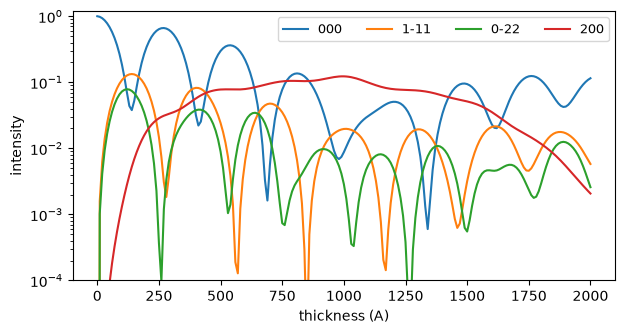

In [9]:
hkl = dyn['hkl'].numpy()
beams = {'000': None, '1-11': (1, -1, 1), '0-22': (0, -2, 2), '200': (2, 0, 0)}
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, h in beams.items():
    if h is None:
        curve = dyn['intensity_000'].numpy()
    else:
        curve = dyn['intensity'][:, np.where((hkl == h).all(1))[0][0]].numpy()
    ax.plot(thicknesses, curve, label=label)
ax.set_xlabel('thickness (A)')
ax.set_ylabel('intensity')
ax.set_yscale('log')
ax.set_ylim(1e-4, 1.2)
ax.legend(ncol=4, fontsize=9);

# Tilt series

Silicon [011] at 500 A, tilted in steps of 0.5 degrees. The strongly excited reflections follow the Laue circle across the pattern.

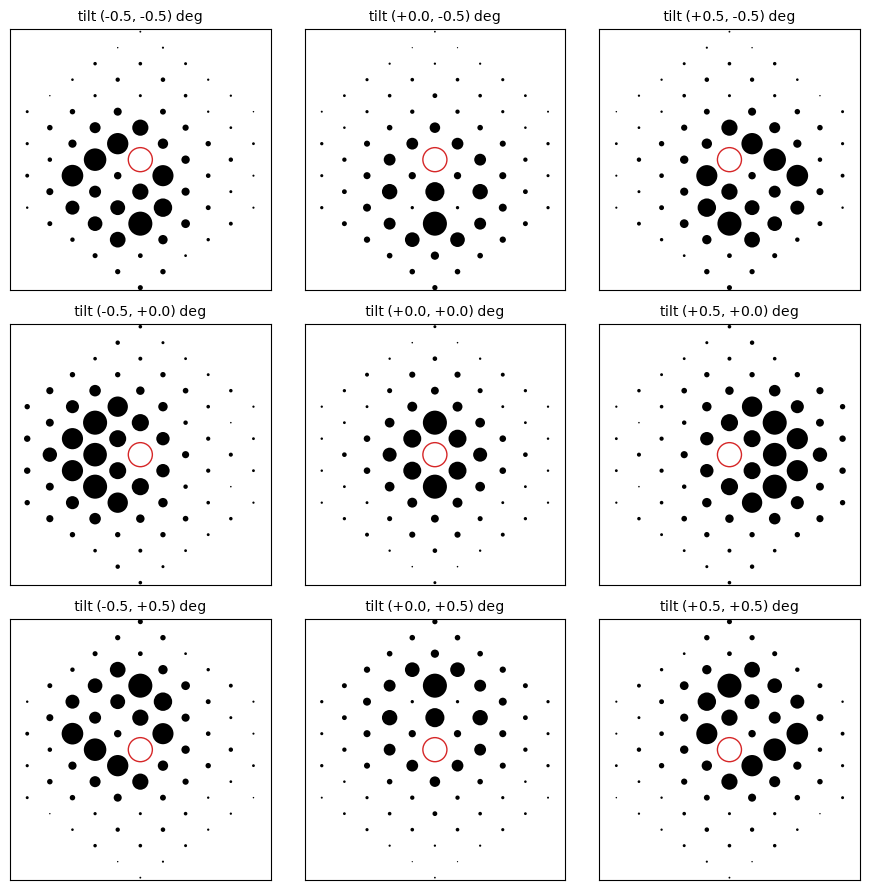

In [10]:
steps = (-0.5, 0.0, 0.5)
patterns, intensity, titles = [], [], []
for ty in steps:
    row_p, row_i, row_t = [], [], []
    for tx in steps:
        d = bloch.dynamical_pattern(
            si, orientation(si, (0, 1, 1), tilt_deg=(tx, ty)), 500.0, energy_ev=energy_ev, k_max=1.5
        )
        row_p.append(d)
        row_i.append(d['intensity'][0])
        row_t.append('tilt (%+.1f, %+.1f) deg' % (tx, ty))
    patterns.append(row_p)
    intensity.append(row_i)
    titles.append(row_t)
fig, axs = plot_spots(patterns, titles, intensity=intensity, num_labels=0, axsize=3.0)

# CBED

Convergent beam patterns of silicon [011], 3 mrad semiangle. The disks fill with the rocking curve of each reflection over the incident directions in the cone.

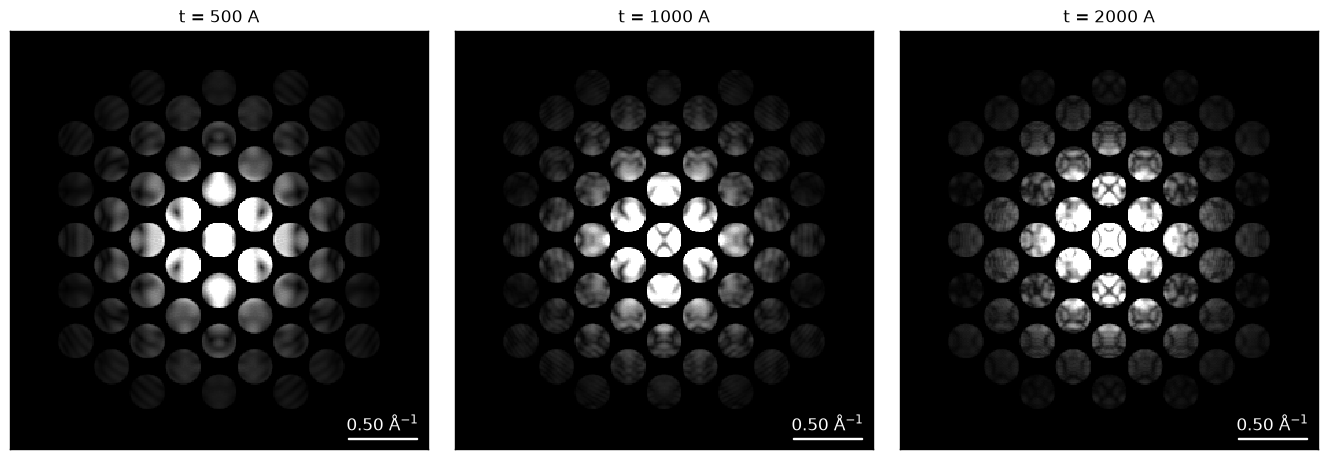

In [11]:
cbed_thickness = [500.0, 1000.0, 2000.0]
cbed = bloch.calculate_cbed(
    si,
    q_110,
    cbed_thickness,
    energy_ev=energy_ev,
    semiconv_mrad=3.0,
    n_rings=16,              # incident directions sampled in the cone
    k_max=1.3,
)
fig, ax = show_2d(
    [p**0.4 for p in cbed['pattern']],
    title=['t = %d A' % t for t in cbed_thickness],
    cmap='gray',
    scalebar={'sampling': cbed['sampling'], 'units': '1/A'},
    axsize=(4.5, 4.5),
)

LACBED: the rocking surface of one reflection over a 10 mrad aperture, here the direct beam and the 1-11 reflection.

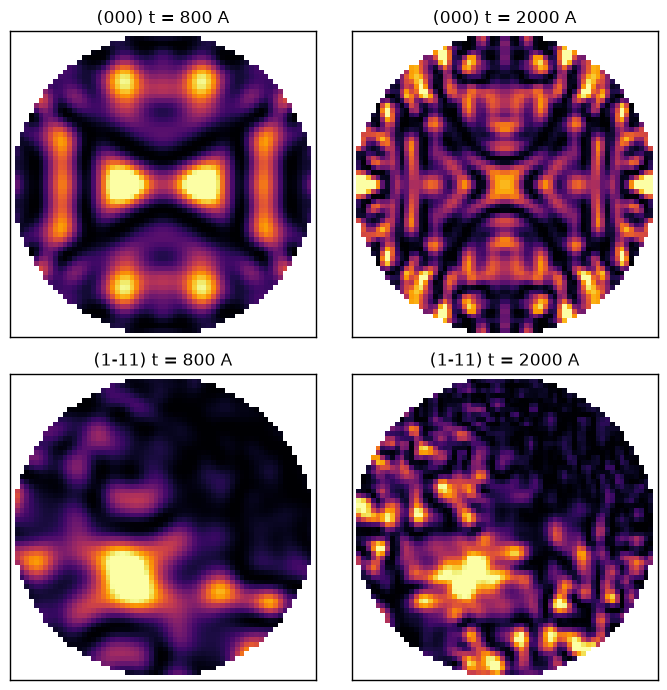

In [12]:
lacbed = {
    hkl: bloch.calculate_lacbed(
        si,
        q_110,
        [800.0, 2000.0],
        hkl=hkl,
        energy_ev=energy_ev,
        semiconv_mrad=10.0,
        n_pixels=64,
        k_max=1.3,
    )
    for hkl in [(0, 0, 0), (1, -1, 1)]
}
fig, ax = show_2d(
    [[out['disk'][0], out['disk'][1]] for out in lacbed.values()],
    title=[['(%d%d%d) t = %d A' % (*hkl, t) for t in (800, 2000)] for hkl in lacbed],
    cmap='inferno',
    axsize=(3.5, 3.5),
)

# Kossel patterns

At convergence angles well beyond the Bragg angles the disks overlap completely, and the bright field becomes a map of deficiency lines, one for every reflection at its Bragg condition.

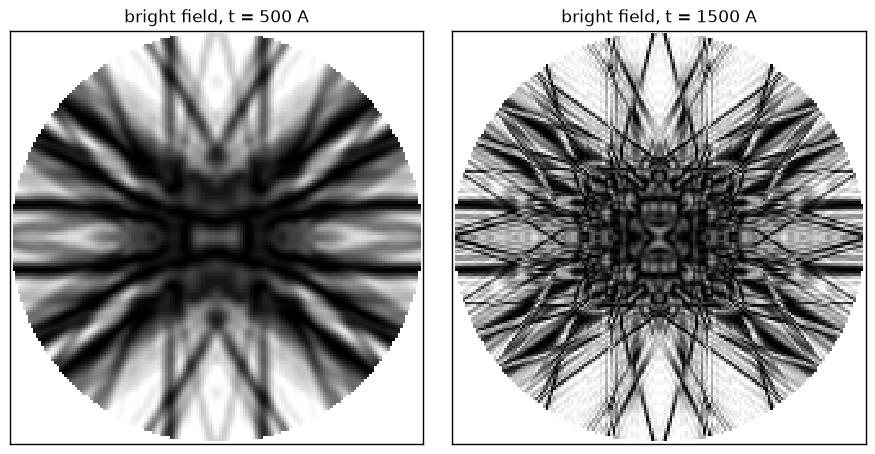

In [13]:
kossel = bloch.calculate_kossel(
    si,
    q_110,
    [500.0, 1500.0],
    energy_ev=energy_ev,
    semiconv_mrad=40.0,
    n_pixels=160,
    k_max=1.2,
    progress_bar=False,
)
fig, ax = show_2d(
    list(kossel['bright_field']),
    title=['bright field, t = %d A' % t for t in kossel['thicknesses']],
    cmap='gray',
    axsize=(4.5, 4.5),
)

The bright field over all incident directions is stored once in a reference pattern. Kossel patterns of any orientation are then read from it in milliseconds, which is fast enough to build matching libraries.

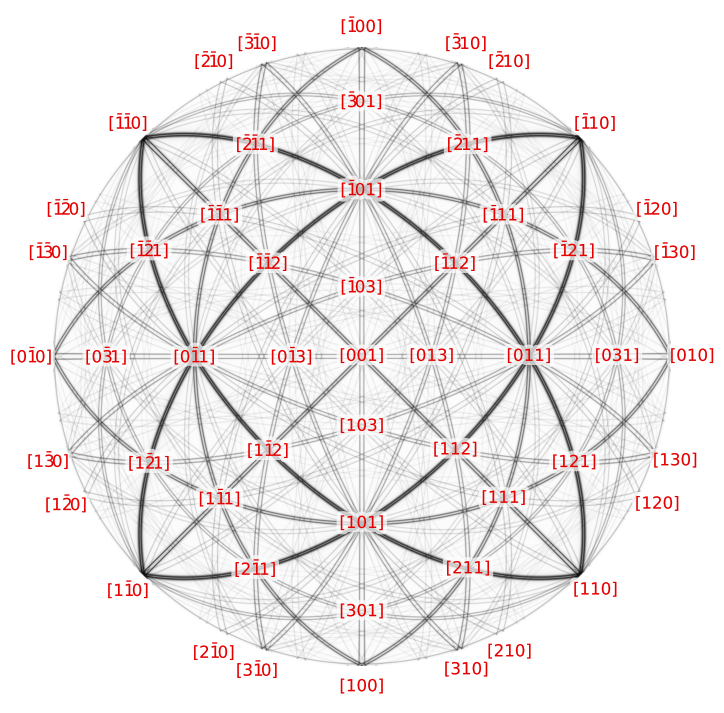

In [14]:
reference = bloch.calculate_kossel_reference(
    si,
    500.0,
    energy_ev=energy_ev,
    angle_step_mrad=2.0,
    k_max=1.2,
    progress_bar=False,
)
lines = bloch.kossel_lines(si, 500.0, energy_ev=energy_ev, k_max=1.2)
fig, ax = bloch.plot_kossel_reference(reference, si, lines=lines, max_index=3)

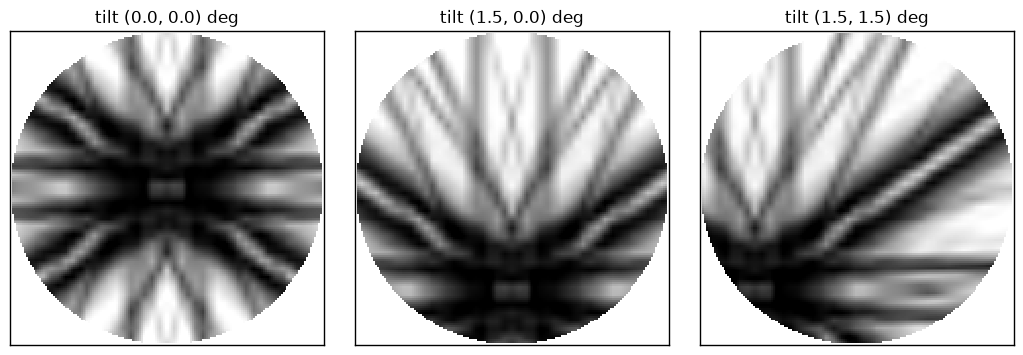

In [15]:
tilts = [(0.0, 0.0), (1.5, 0.0), (1.5, 1.5)]
patterns = [
    bloch.kossel_from_reference(
        reference,
        orientation(si, (0, 1, 1), tilt_deg=t),
        semiconv_mrad=40.0,
        n_pixels=160,
    )['bright_field']
    for t in tilts
]
fig, ax = show_2d(
    patterns,
    title=['tilt (%.1f, %.1f) deg' % t for t in tilts],
    cmap='gray',
    axsize=(3.5, 3.5),
)